## Load & Download

In [ ]:
from huggingface_hub import HfApi, snapshot_download

repo_id = "jasongzy/RaBit"
repo_type = "dataset"

def baixar_itens(itens, destino="./RaBit_download", max_workers=8):
    """
    Baixa uma lista de arquivos e/ou pastas do repositório.

    itens: lista de caminhos relativos à raiz do repo, por exemplo
           ["3DBiCar/1006", "3DBiCar/1007/pose/3djoint.npy", "README.md"]
    """
    api = HfApi()
    todos = api.list_repo_files(repo_id, repo_type=repo_type)
    conjunto = set(todos)

    padroes = []
    for item in itens:
        item = item.strip("/")
        if item in conjunto:
            # é um arquivo exato
            padroes.append(item)
        elif any(f.startswith(item + "/") for f in todos):
            # é uma pasta: tudo que estiver dentro dela
            padroes.append(f"{item}/*")
        else:
            print(f"Aviso: '{item}' não encontrado no repositório, ignorado.")

    if not padroes:
        print("Nada para baixar.")
        return None

    caminho = snapshot_download(
        repo_id=repo_id,
        repo_type=repo_type,
        allow_patterns=padroes,
        local_dir=destino,
        max_workers=max_workers,
    )
    print(f"Download concluído em: {caminho}")
    return caminho


# Exemplo de uso
itens = [
    "3DBiCar/100",
    "3DBiCar/1005",
    "3DBiCar/1217",
]
baixar_itens(itens)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 60 files:   0%|          | 0/60 [00:00<?, ?it/s]

Download concluído em: /content/RaBit_download


'/content/RaBit_download'

In [ ]:
"""
Simple 3DBiCar 2D keypoint extraction (replaces the notebook readjson / polygon2seg /
reshape_image_and_anno / show_* code and the Dataset class).

Reads   <folder>/image/raw_image.jpeg  and  <folder>/image/annotation.json
Writes  into --out (default: ./out):
    masked.png       512x512 cropped/padded image, background removed with the polygon mask
    keypoints.txt    "index x y status" in the 512x512 frame
                     status: -1 = does not exist, 0 = visible, 1 = hidden/covered
    masked_kps.png   masked.png with the keypoints drawn (blue = visible, green = hidden)

Usage:
    python extract_kps.py ./3DBiCar/<instance> [--out out] [--size 512]

Needs only: numpy, opencv-python, pillow.
"""
import argparse
import json
import math
import os

import cv2
import numpy as np
from PIL import Image, ImageDraw

NUM_KPS = 24


def read_annotation(json_path):
    """Returns polygon (N,2) and keypoints (24,3) = x, y, status in raw-image pixels."""
    with open(json_path, "r", encoding="utf-8") as f:
        data = json.load(f)
    polygon = None
    kps = -np.ones((NUM_KPS, 3))
    for s in data["shapes"]:
        if s["shape_type"] == "polygon":
            polygon = np.array(s["points"], dtype=np.float64)
        elif s["shape_type"] == "point":
            _, index, hidden = s["label"].split("-")
            index = int(index.split("_")[-1])
            hidden = int(hidden[-1] == "1")
            kps[index] = [s["points"][0][0], s["points"][0][1], hidden]
    if polygon is None:
        raise ValueError("no polygon found in annotation")
    return polygon, kps


def process(folder, out_dir, size=512):
    img = np.array(Image.open(os.path.join(folder, "image", "raw_image.jpeg")).convert("RGB"))
    polygon, kps = read_annotation(os.path.join(folder, "image", "annotation.json"))
    H, W = img.shape[:2]

    # polygon -> binary mask (0/1)
    m = Image.new("L", (W, H), 0)
    ImageDraw.Draw(m).polygon([tuple(p) for p in polygon], outline=0, fill=1)
    mask = np.array(m, dtype=np.uint8)

    # crop to the polygon bounding box
    x1, y1 = np.floor(polygon.min(axis=0)).astype(int)
    x2, y2 = np.ceil(polygon.max(axis=0)).astype(int)
    x1, y1, x2, y2 = max(x1, 0), max(y1, 0), min(x2, W), min(y2, H)
    img, mask = img[y1:y2, x1:x2], mask[y1:y2, x1:x2]
    valid = kps[:, 2] != -1
    kps[valid, :2] -= [x1, y1]

    # pad to a square (image: white, mask: 0)
    h, w = mask.shape
    dif = abs(h - w)
    a, b = dif // 2, dif - dif // 2
    if h > w:   # pad left/right
        img = cv2.copyMakeBorder(img, 0, 0, a, b, cv2.BORDER_CONSTANT, value=(255, 255, 255))
        mask = cv2.copyMakeBorder(mask, 0, 0, a, b, cv2.BORDER_CONSTANT, value=0)
        kps[valid, 0] += a
    else:       # pad top/bottom
        img = cv2.copyMakeBorder(img, a, b, 0, 0, cv2.BORDER_CONSTANT, value=(255, 255, 255))
        mask = cv2.copyMakeBorder(mask, a, b, 0, 0, cv2.BORDER_CONSTANT, value=0)
        kps[valid, 1] += a

    # resize to size x size
    ratio = size / max(h, w)
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)
    mask = cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)
    kps[valid, :2] *= ratio

    masked = img * mask[:, :, None]

    # draw keypoints on a copy of the masked image
    drawn = masked.copy()
    for i, (x, y, s) in enumerate(kps):
        if s == -1:
            continue
        color = (0, 0, 255) if s == 0 else (0, 255, 0)   # RGB: blue visible, green hidden
        cv2.circle(drawn, (int(round(x)), int(round(y))), 2, color, thickness=4)
        cv2.putText(drawn, str(i), (int(x) + 5, int(y) - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1, cv2.LINE_AA)

    os.makedirs(out_dir, exist_ok=True)
    Image.fromarray(masked).save(os.path.join(out_dir, "drawing.png"))
    Image.fromarray(drawn).save(os.path.join(out_dir, "joints_in_drawing.png"))
    with open(os.path.join(out_dir, "2d_joints.txt"), "w") as f:
        f.write("# index x y status (-1 missing, 0 visible, 1 hidden)\n")
        for i, (x, y, s) in enumerate(kps):
            f.write(f"{i} {x:.3f} {y:.3f} {int(s)}\n")
    return masked, kps


# if __name__ == "__main__":
#     ap = argparse.ArgumentParser()
#     ap.add_argument("folder", help="3DBiCar instance folder")
#     ap.add_argument("--out", default="out")
#     ap.add_argument("--size", type=int, default=512)
#     args = ap.parse_args()
#     _, kps = process(args.folder, args.out, args.size)
#     print(f"Saved masked.png, keypoints.txt, masked_kps.png in {args.out}/")

f_id = "1217"
_, kps = process("RaBit_download/3DBiCar/"+f_id, f_id+"_out", 512)

In [ ]:
%cd RaBit_download

/content/RaBit_download


In [ ]:
import shutil
shutil.make_archive('100', 'zip', './3DBiCar', '100')


'/content/RaBit_download/100.zip'

In [ ]:
import json
import numpy as np
import cv2
from PIL import Image, ImageDraw


def readjson(filename):
	with open(filename, 'r', encoding='utf-8') as f:
		data = json.load(f)
	polygon=None
	kps = np.ones((24,3))*-1 #x1,y1,status (-1:not exist. 0/1: covered or not)
	for x in data['shapes']:
		if x['shape_type']=='polygon':
			polygon = x['points']
		elif x['shape_type']=='point':
			_,index,hidden = x['label'].split('-')
			index = int(index.split('_')[-1])
			hidden = int(hidden[-1]=='1')
			kps[index] = np.array([x['points'][0][0],x['points'][0][1],hidden])

	poly = np.array(polygon)
	polymax = np.max(poly,axis=0).tolist()
	polymin = np.min(poly,axis=0).tolist()
	bbox = polymin+polymax  #x1 y1 x2 y2
	return polygon,kps,bbox

def polygon2seg(image,polygon):
	for i in range(len(polygon)):
		polygon[i] = tuple(polygon[i])
	mask = Image.new('L', (image.width, image.height), 0)
	ImageDraw.Draw(mask).polygon(polygon, outline=0, fill=1)
	return np.array(mask)

def show_seg(image,mask):
	image = np.array(image).copy()
	mask = np.array(mask)
	mask = mask[:,:,np.newaxis]
	masked_image = image*mask
	Image.fromarray(masked_image)
	masked_image = Image.fromarray(masked_image)
	display(masked_image)
	return

def show_kps(image,kps):
	image = np.array(image).copy()
	for x,y,h in kps:
		y,x,h = int(y),int(x),int(h)
		if h==-1:
			continue
		point_size=2
		if h==0:
			point_color=(0,0,255)
		else:
			point_color=(0,255,0)
		cv2.circle(image,(x,y),point_size,point_color,thickness=4)
	pil_image = Image.fromarray(image)
	display(pil_image)
	return

def reshape_image_and_anno(image,mask,kps,bbox,size=512):
	def move_kps(kps,move=None,ratio=None):
		if move is not None:
			for i in range(len(kps)):
				if kps[i][2]!=-1:
					kps[i][:2] += move
		elif ratio is not None:
			for i in range(len(kps)):
				if kps[i][0]!=-1:
					kps[i][:2] *= ratio
		return kps
	image = np.array(image)
	mask = np.array(mask)
	y1,x1,y2,x2 = bbox
	image = image[x1:x2, y1:y2]
	mask = mask[x1:x2,y1:y2]
	kps = move_kps(kps,move=-np.array([y1,x1]))

	#diff
	dx = abs(x2-x1)
	dy = abs(y2-y1)
	dif = abs(dx-dy)
	if dx>dy:
		image = cv2.copyMakeBorder(image, 0, 0, int(dif//2), int(dif-dif//2), cv2.BORDER_CONSTANT, value=(255,255,255))
		mask = cv2.copyMakeBorder(mask, 0, 0, int(dif//2), int(dif-dif//2), cv2.BORDER_CONSTANT, value=(255,255,255))
		kps = move_kps(kps,move=np.array([int(dif//2),0]))
	else:
		image = cv2.copyMakeBorder(image, int(dif//2), int(dif-dif//2), 0, 0, cv2.BORDER_CONSTANT, value=(255,255,255))
		mask = cv2.copyMakeBorder(mask, int(dif//2), int(dif-dif//2), 0, 0, cv2.BORDER_CONSTANT, value=(255,255,255))
		kps = move_kps(kps,move=np.array([0,int(dif//2)]))

	#ratio
	ratio = size/max(dx,dy)
	image = cv2.resize(image,(size,size))
	mask = cv2.resize(mask,(size,size))
	kps = move_kps(kps,ratio=ratio)
	return image,mask,kps

"""
def __name__=='__main__':
	image = Image.open("raw_image.jpeg").convert('RGB')
	polygon,kps,bbox = readjson("annotation.json")
	mask = polygon2seg(image,polygon)
	# show_seg(image,mask)
	# show_kps(image,kps)

	size=512
	nimage,nmask,nkps = reshape_image_and_anno(image,mask,kps,size)
	show_seg(nimage,nmask)
	show_kps(nimage,nkps)


"""


'\ndef __name__==\'__main__\':\n\timage = Image.open("raw_image.jpeg").convert(\'RGB\')\n\tpolygon,kps,bbox = readjson("annotation.json")\n\tmask = polygon2seg(image,polygon)\n\t# show_seg(image,mask)\n\t# show_kps(image,kps)\n\n\tsize=512\n\tnimage,nmask,nkps = reshape_image_and_anno(image,mask,kps,size)\n\tshow_seg(nimage,nmask)\n\tshow_kps(nimage,nkps)\n\n\n'

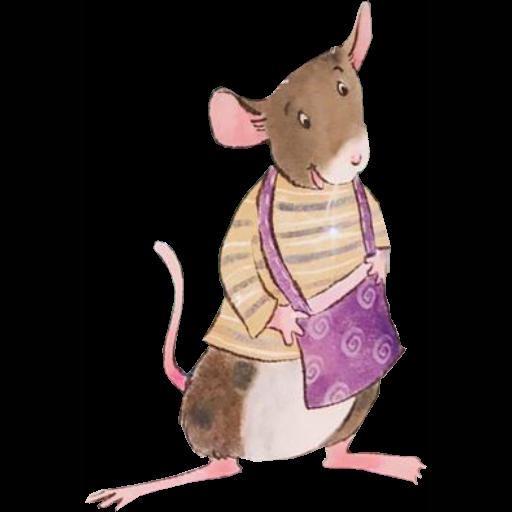

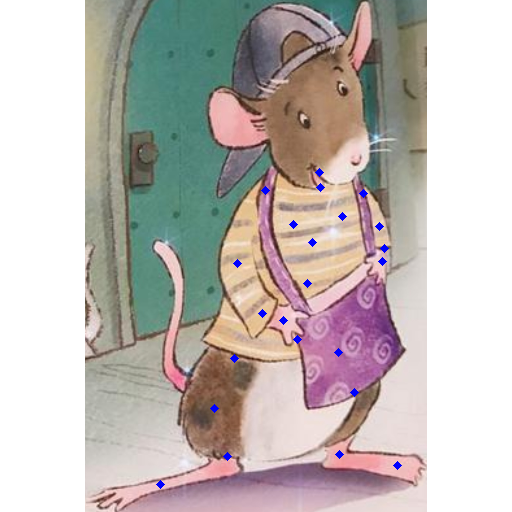

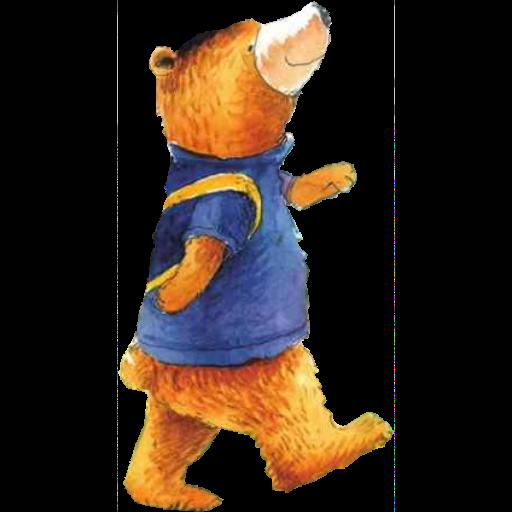

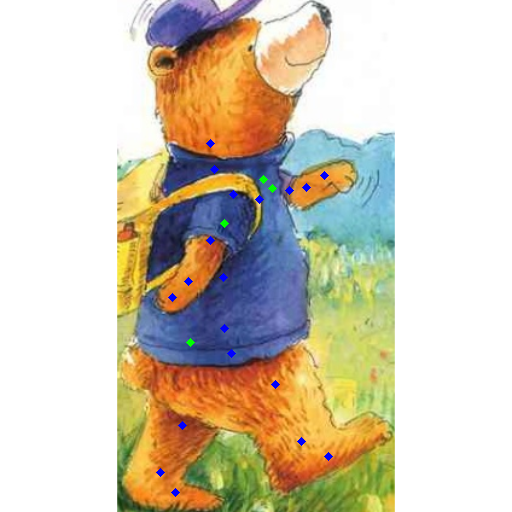

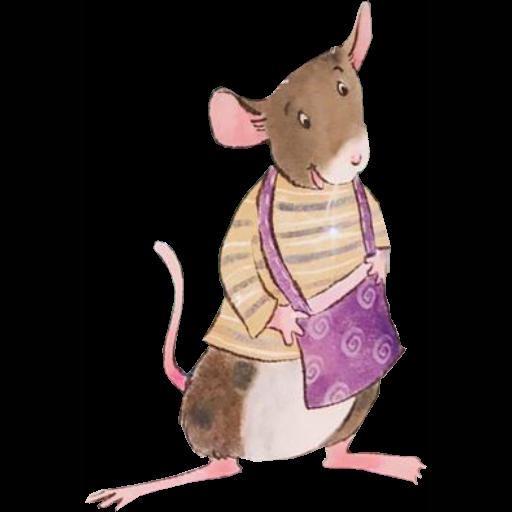

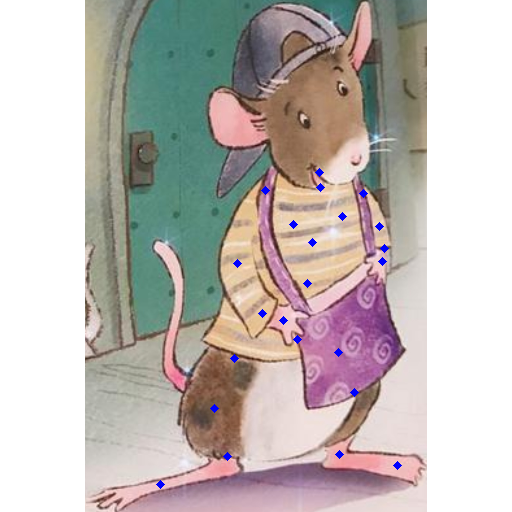

input_image torch.Size([2, 512, 512, 3])
input_mask torch.Size([2, 512, 512])
input_kps torch.Size([2, 24, 3])
beta torch.Size([2, 100])
theta torch.Size([2, 3, 24])
Tbody_uv torch.Size([2, 2048, 2048, 3])
Pbody_uv torch.Size([2, 2048, 2048, 3])


In [ ]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import cv2
from PIL import Image
import json
# import openmesh as om
import pdb
# from utils import *

class BiCarDataset(Dataset):
    def __init__(self, dataset_folder,input_size=512):
        self.dataset_folder = dataset_folder
        self.data_index_list = os.listdir(dataset_folder)
        self.input_size = input_size

    def __getitem__(self, index):
        instance_index = self.data_index_list[index]
        instance_folder = os.path.join(self.dataset_folder,instance_index)
        input_kps= np.zeros(1)
        # image/mask/annotation
        #processed images and mask
        #input_image = cv2.imread(os.path.join(instance_folder,'image','image_reshape512.jpeg'))
        #input_mask = cv2.imread(os.path.join(instance_folder,'image','mask512.png'))
        #processed image in dataloader
        image = Image.open(os.path.join(instance_folder,'image','raw_image.jpeg')).convert('RGB')
        polygon,kps,bbox = readjson(os.path.join(instance_folder,'image','annotation.json'))
        mask = polygon2seg(image,polygon)
        input_image,input_mask,input_kps = reshape_image_and_anno(image,mask,kps,bbox,self.input_size)

        # this two function can be used to visualize
        show_seg(input_image,input_mask)
        show_kps(input_image,input_kps)

        #params: shape and pose
        beta = np.load(os.path.join(instance_folder,'params','beta.npy'))[:100]
        theta = np.load(os.path.join(instance_folder,'params','pose.npy')).reshape(3,24)

        #mesh: Here we only read points and uvmap of body only.
        #Tbody: T-pose body; Pbody: Posed body.
        # tmesh = om.read_polymesh(os.path.join(instance_folder,'tpose','m.obj'))
        # tbody_points =  tmesh.points()
        tbody_uv = cv2.imread(os.path.join(instance_folder,'tpose','m.BMP'))

        # pmesh = om.read_polymesh(os.path.join(instance_folder,'pose','m.obj'))
        # pbody_points =  pmesh.points()
        pbody_uv = cv2.imread(os.path.join(instance_folder,'pose','m.BMP'))


        return {'input_image':input_image,
                'input_mask':input_mask,
                'input_kps':input_kps,
                #'json_annotation':annotation,
                'beta':beta,
                'theta':theta,
                # 'Tbody_points':tbody_points,
                'Tbody_uv':tbody_uv,
                # 'Pbody_points':pbody_points,
                'Pbody_uv':pbody_uv
                }

    def __len__(self):
        return len(self.data_index_list)

dataset = BiCarDataset('./3DBiCar')
batch_size = 2
dataset.__getitem__(1)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

for batch in dataloader:
    for item in batch:
        print(item,batch[item].shape)
    break


## Matching

In [ ]:
!pip install opencv-contrib-python --upgrade

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 82.1/82.1 MB 49.5 MB/s  0:00:01
  Attempting uninstall: opencv-contrib-python
    Found existing installation: opencv-contrib-python 4.14.0.94
    Uninstalling opencv-contrib-python-4.14.0.94:
      Successfully uninstalled opencv-contrib-python-4.14.0.94


In [ ]:
import cv2 as cv2 # opencv computer vision library
from skimage import io # for io.imread
from matplotlib import pyplot as plt # for plotting
import numpy as np

In [ ]:
def imshow(
    images: list[np.ndarray] | np.ndarray,
    titles: list[str] | str | None = None,
    nrows: int = 0,
    ncols: int = 0,
    figsize: (float, float) = (10, 4),
):
    """Plot a multiple images with titles.

    Parameters
    ----------
    images : image list
    titles : title list
    ncols : number of columns of subplots wanted in the display
    nrows : number of rows of subplots wanted in the figure
    figsize : size of the figure
    """
    if not isinstance(images, list):
        images = [images]
    if titles is not None and not isinstance(titles, list):
        titles = [titles]

    if ncols == 0 and nrows == 0:
        ncols = len(images)
        nrows = 1
    if ncols == 0:
        ncols = len(images) // nrows
    if nrows == 0:
        nrows = len(images) // ncols

    fig, axeslist = plt.subplots(
        ncols=ncols, nrows=nrows, squeeze=False, figsize=figsize
    )

    for i, image in enumerate(images):
        axeslist.ravel()[i].imshow(image, cmap=plt.gray(), vmin=0, vmax=255)
        if titles is not None:
            axeslist.ravel()[i].set_title(titles[i])
        axeslist.ravel()[i].set_axis_off()
    plt.tight_layout()  # optional

    return fig, axeslist


(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: >, <Axes: >]], dtype=object))

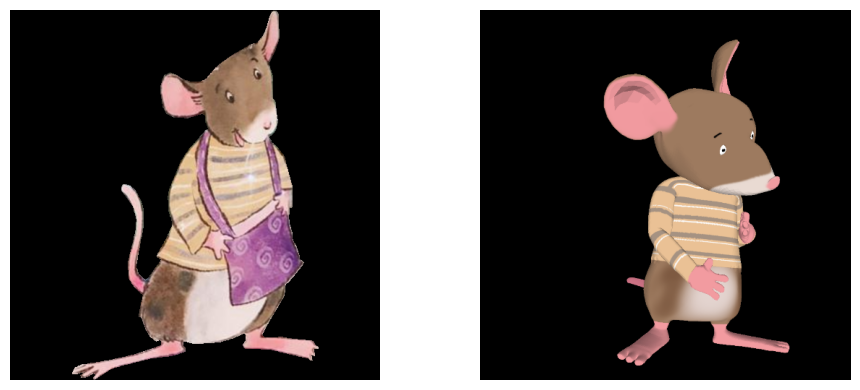

In [ ]:
im1 = io.imread('drawing.png')
im2 = io.imread('model.bmp')

# Get the height and width of im1
height, width = im1.shape[:2]

# Resize im2 to match im1's resolution
im2 = cv2.resize(im2, (width, height), interpolation=cv2.INTER_LINEAR)

imshow([im1, im2])

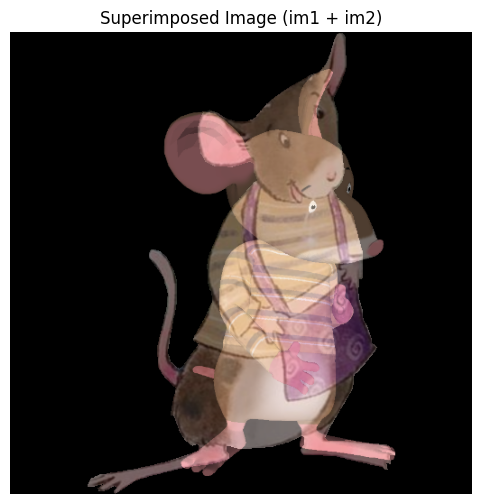

In [ ]:
# Superimpose im1 and im2 with 50% transparency (alpha = 0.5, beta = 0.5)
alpha = 0.5
beta = 1.0 - alpha
superimposed_img = cv2.addWeighted(im1, alpha, im2, beta, 0.0)

# Display the superimposed image
plt.figure(figsize=(6, 6))
plt.imshow(superimposed_img)
plt.title("Superimposed Image (im1 + im2)")
plt.axis("off")
plt.show()

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: >, <Axes: >]], dtype=object))

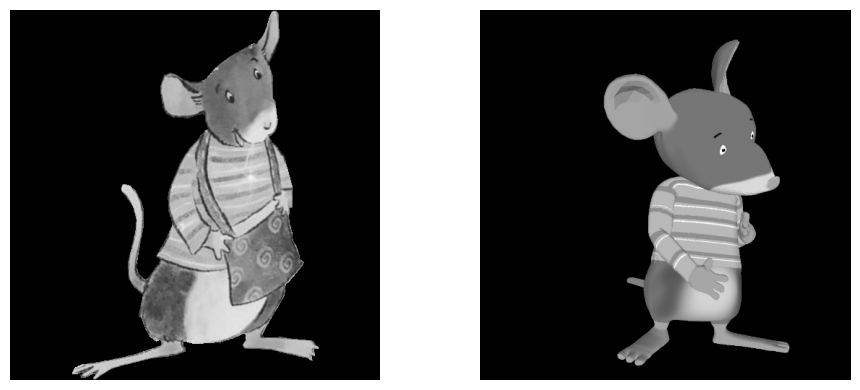

In [ ]:
im1_gray = cv2.cvtColor(im1, cv2.COLOR_BGR2GRAY)
im2_gray = cv2.cvtColor(im2, cv2.COLOR_BGR2GRAY)
imshow([im1_gray, im2_gray])

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: >, <Axes: >]], dtype=object))

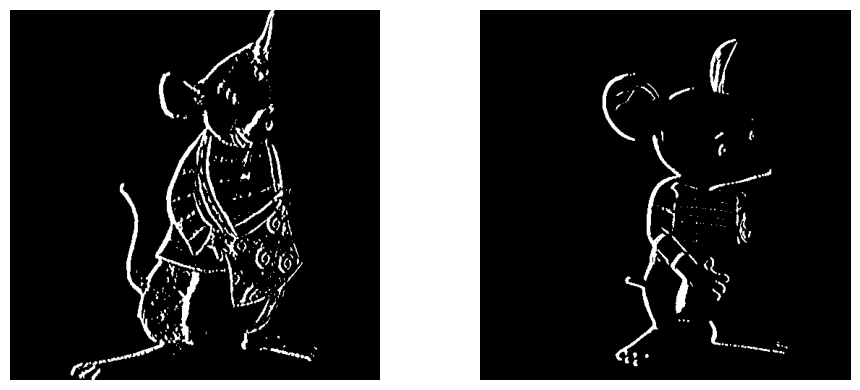

In [ ]:

thr = 500
im1_sobel = cv2.Sobel(im1_gray, cv2.CV_64F, 1, 0, ksize=5)
im1_sobel = np.where(im1_sobel > thr, 255.0, 0.0)
im2_sobel = cv2.Sobel(im2_gray, cv2.CV_64F, 1, 0, ksize=5)
im2_sobel = np.where(im2_sobel > thr, 255.0, 0.0)

imshow([im1_sobel, im2_sobel])

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'im1 Silhouette'}>,
         <Axes: title={'center': 'im2 Silhouette'}>]], dtype=object))

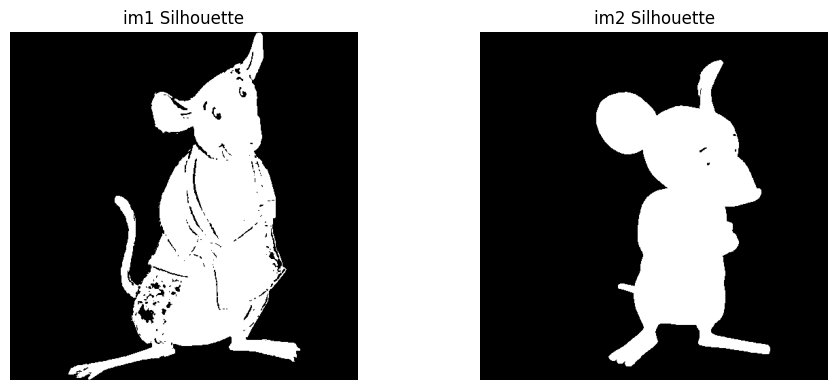

In [ ]:
# Apply Otsu's thresholding to extract binary silhouettes
_, im1_silhouette = cv2.threshold(im1_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
_, im2_silhouette = cv2.threshold(im2_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Display the extracted silhouettes
imshow([im1_silhouette, im2_silhouette], ["im1 Silhouette", "im2 Silhouette"])

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'im1 External Contour'}>,
         <Axes: title={'center': 'im2 External Contour'}>]], dtype=object))

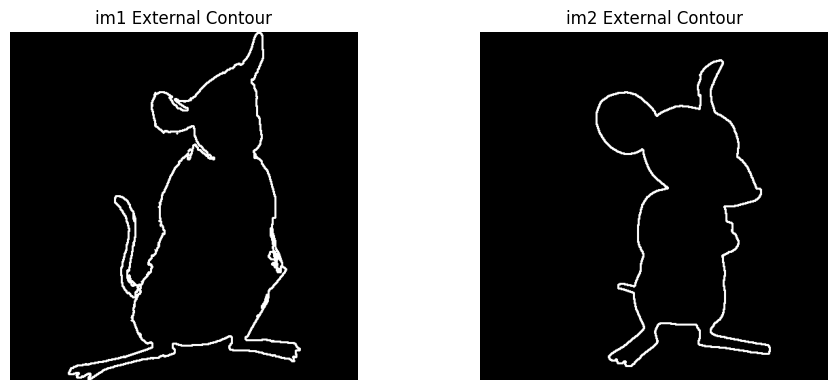

In [ ]:
# Find external contours for im1 and im2 silhouettes
contours1, _ = cv2.findContours(im1_silhouette, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours2, _ = cv2.findContours(im2_silhouette, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Create empty black images to draw the contours
im1_contours = np.zeros_like(im1_silhouette)
im2_contours = np.zeros_like(im2_silhouette)

# Draw the external contours in white (255) with thickness 2
cv2.drawContours(im1_contours, contours1, -1, 255, 2)
cv2.drawContours(im2_contours, contours2, -1, 255, 2)

# Display the contour results
imshow([im1_contours, im2_contours], ["im1 External Contour", "im2 External Contour"])

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'Blurred im1'}>,
         <Axes: title={'center': 'Blurred im2'}>]], dtype=object))

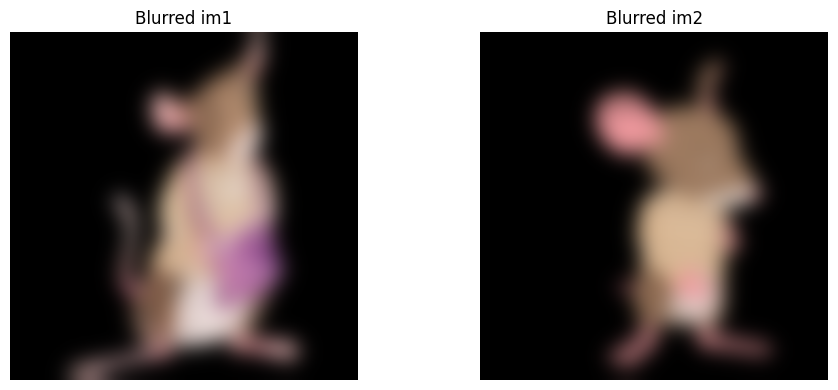

In [ ]:
im1_blur = cv2.GaussianBlur(im1, (101, 101), 0)
im2_blur = cv2.GaussianBlur(im2, (101, 101), 0)

imshow([im1_blur, im2_blur], ["Blurred im1", "Blurred im2"])

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'Max Pooled im1'}>,
         <Axes: title={'center': 'Max Pooled im2'}>]], dtype=object))

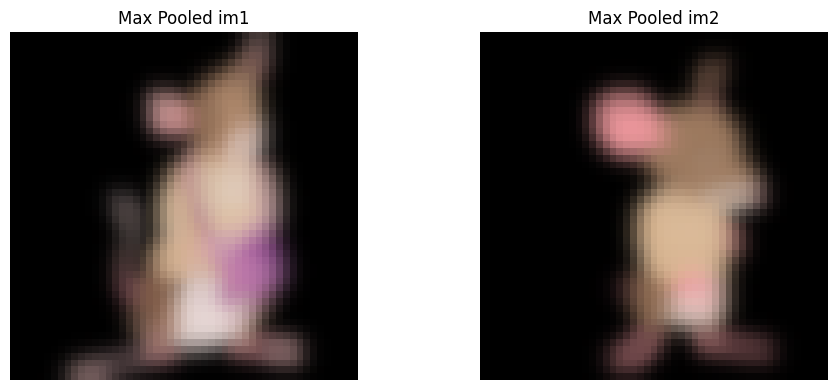

In [ ]:
import torch
import torch.nn.functional as F

def apply_max_pool(img, kernel_size=4):
    # Convert HWC to BCHW expected by PyTorch
    tensor_img = torch.from_numpy(img).permute(2, 0, 1).unsqueeze(0).float()
    # tensor_img = torch.from_numpy(img).unsqueeze(0).float()
    # Apply max pooling
    pooled_tensor = F.max_pool2d(tensor_img, kernel_size=kernel_size, stride=kernel_size)
    # Convert back to HWC NumPy array of uint8
    pooled_img = pooled_tensor.squeeze(0).permute(1, 2, 0).byte().numpy()
    # pooled_img = pooled_tensor.squeeze(0).byte().numpy()
    return pooled_img

im1_pooled = apply_max_pool(im1_blur , kernel_size=10)
im2_pooled = apply_max_pool(im2_blur , kernel_size=10)

imshow([im1_pooled, im2_pooled], ["Max Pooled im1", "Max Pooled im2"])

(<Figure size 1000x400 with 2 Axes>,
 array([[<Axes: title={'center': 'Segmented im1 (K=3)'}>,
         <Axes: title={'center': 'Segmented im2 (K=3)'}>]], dtype=object))

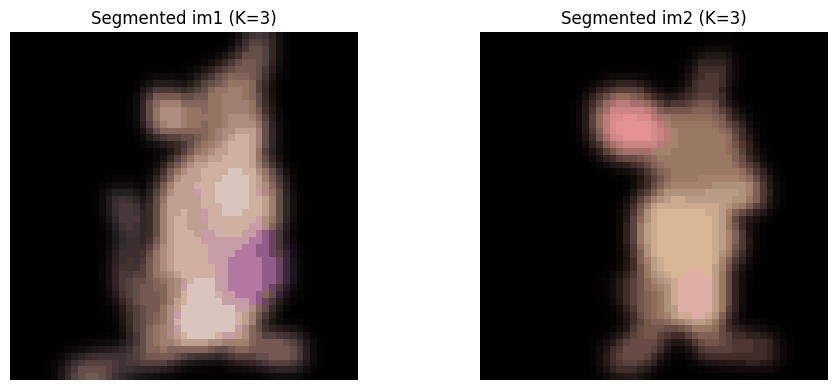

In [ ]:
def segment_kmeans(img, K=3):
    # Reshape the image to a 2D array of pixels with 3 color channels
    pixel_vals = img.reshape((-1, 3))
    # Convert to float32 expected by cv2.kmeans
    pixel_vals = np.float32(pixel_vals)

    # Define criteria and apply kmeans
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
    compactness, labels, centers = cv2.kmeans(pixel_vals, K, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

    # Convert back to 8-bit values and map labels to center values
    centers = np.uint8(centers)
    segmented_data = centers[labels.flatten()]

    # Reshape back to the original image dimensions
    segmented_image = segmented_data.reshape((img.shape))
    return segmented_image

im1_seg = segment_kmeans(im1_pooled, K=200)
im2_seg = segment_kmeans(im2_pooled, K=200)

imshow([im1_seg, im2_seg], ["Segmented im1 (K=3)", "Segmented im2 (K=3)"])

541 440


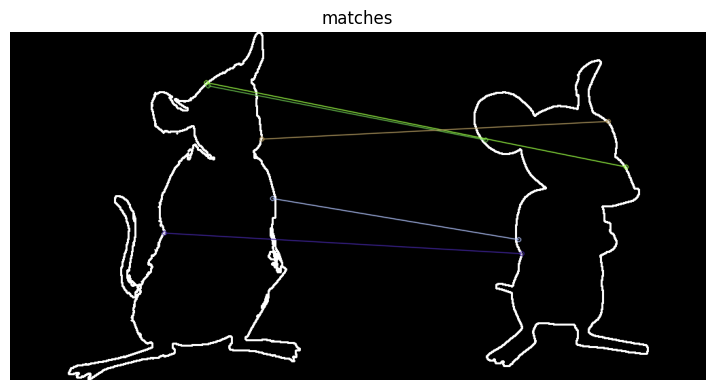

In [ ]:
def matching(img1, img2):
    # Convert images to 8-bit unsigned integer (CV_8U) required by AKAZE
    img1_8u = img1.astype(np.uint8)
    img2_8u = img2.astype(np.uint8)

    # Try to initialize AKAZE from standard cv2 or cv2.xfeatures2d fallback
    if hasattr(cv2, 'AKAZE_create'):
        akaze = cv2.AKAZE_create()
    elif hasattr(cv2, 'xfeatures2d') and hasattr(cv2.xfeatures2d, 'AKAZE_create'):
        akaze = cv2.xfeatures2d.AKAZE_create()
    else:
        raise AttributeError("O detector AKAZE não foi encontrado no OpenCV instalado. Tente reiniciar o ambiente de execução ou reinstalar o opencv-contrib-python.")

    kp1, des1 = akaze.detectAndCompute(img1_8u, None)
    kp2, des2 = akaze.detectAndCompute(img2_8u, None)
    print(len(kp1), len(kp2))

    bf = cv2.BFMatcher()
    matches = bf.match(des1, des2)
    matches = sorted(matches, key=lambda x: x.distance)
    img = cv2.drawMatches(img1_8u, kp1, img2_8u, kp2, matches[:5], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    imshow([img], ["matches"])


matching(im1_contours, im2_contours)


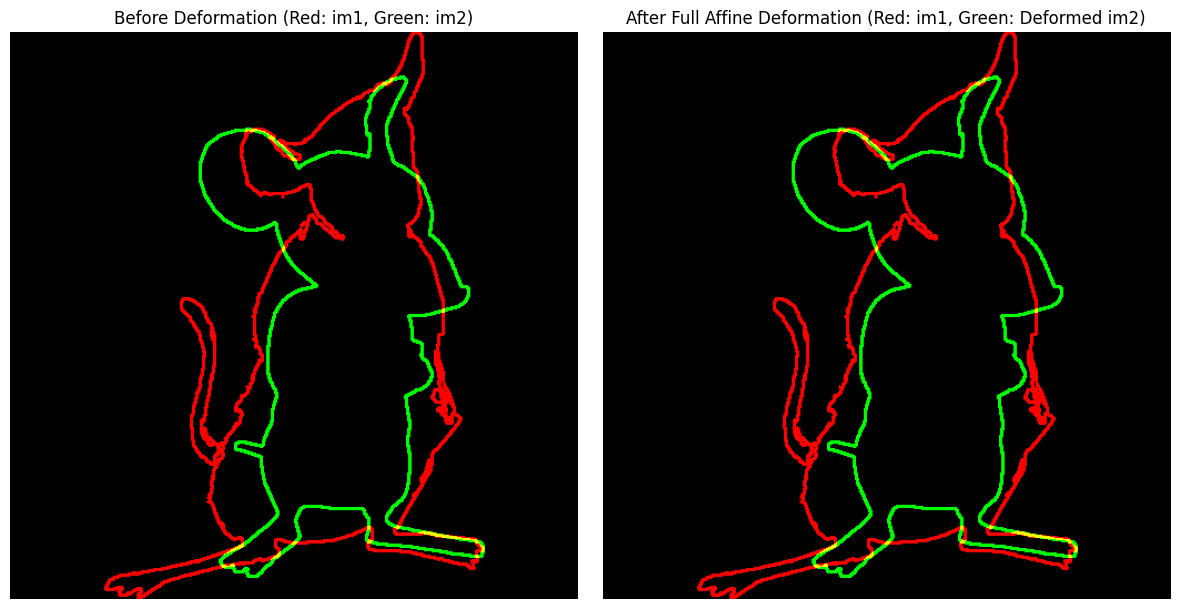

In [ ]:
import numpy as np
import cv2
from matplotlib import pyplot as plt

# Get the list of coordinates (y, x) where the contours are drawn
pts1 = np.argwhere(im1_contours > 0)[:, [1, 0]].astype(np.float32)
pts2 = np.argwhere(im2_contours > 0)[:, [1, 0]].astype(np.float32)

# To match the points, we perform a Procrustes alignment via ICP using a full Affine transformation (including shear)
def iterative_closest_point(pts_src, pts_dst, max_iterations=1000, tolerance=1e-5):
    '''
    Finds the best full affine transformation (translation, rotation, scale, shear) to deform pts_src to match pts_dst.
    '''
    # Initialize transformed points
    src = pts_src.copy()

    for i in range(max_iterations):
        # 1. Find the nearest neighbors in the destination set
        from sklearn.neighbors import NearestNeighbors
        nbrs = NearestNeighbors(n_neighbors=1, algorithm='auto').fit(pts_dst)
        distances, indices = nbrs.kneighbors(src)
        matched_dst = pts_dst[indices.flatten()]

        # 2. Estimate the full affine transformation matrix (including shear/cisalhamento)
        M, inliers = cv2.estimateAffine2D(src, matched_dst, method=cv2.RANSAC, ransacReprojThreshold=5.0)

        if M is None:
            print("M is none")
            break

        # 3. Apply the transformation to the source points
        ones = np.ones((len(src), 1))
        src_hom = np.hstack([src, ones])
        new_src = (M @ src_hom.T).T

        # Check convergence
        mean_error = np.mean(np.sqrt(np.sum((new_src - src)**2, axis=1)))
        src = new_src

        if mean_error < tolerance:
            print(f"Convergence reached after {i+1} iterations.")
            break

    return M, src

# Compute the best full affine deformation matrix (M) from im2_contours to im1_contours
M, deformed_pts = iterative_closest_point(pts2, pts1, tolerance=1e-8)

# Apply the computed full affine deformation matrix to warp the whole im2_contours image
h, w = im1_contours.shape
deformed_im2_contours = cv2.warpAffine(im2_contours, M, (w, h))

# Create a visualization showing the original overlap vs the deformed overlap
overlap_before = cv2.merge([im1_contours, im2_contours, np.zeros_like(im1_contours)])
overlap_after = cv2.merge([im1_contours, deformed_im2_contours, np.zeros_like(im1_contours)])

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(overlap_before)
plt.title("Before Deformation (Red: im1, Green: im2)")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(overlap_after)
plt.title("After Full Affine Deformation (Red: im1, Green: Deformed im2)")
plt.axis("off")

plt.tight_layout()
plt.show()

stage          shape-ctx   Hausdorff  chamfer(px)
original          0.3294        7.00        21.52
affine            0.2007       10.72        18.30
TPS               0.0502       13.28         4.45


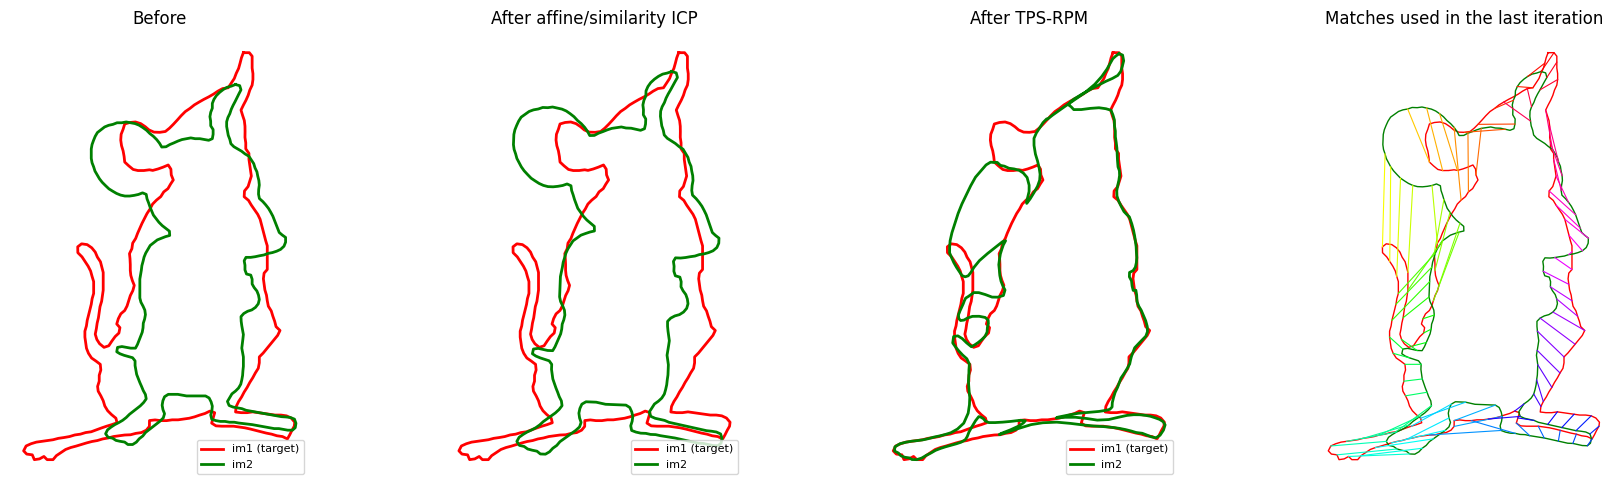

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.optimize import linear_sum_assignment
from sklearn.neighbors import NearestNeighbors

# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
N_PTS      = 300                      # points per contour
N_ITERS    = 12                       # TPS-RPM annealing steps
REGS       = np.geomspace(1.0, 0.005, N_ITERS)  # TPS stiffness (normalized units), high -> low
LAMS       = np.linspace(0.3, 3.0, N_ITERS)     # weight of the position term, low -> high
OUTLIER_C  = 0.55                     # cost of leaving a point unmatched (tail, bag...)
KEEP_Q     = 0.90                     # keep the best 90% of matches at each step
im2_img    = None                     # optional: BGR render of the 3D model, to warp it too

# ----------------------------------------------------------------------------
# 1. Contour extraction
# ----------------------------------------------------------------------------
def clean_outline(img, n=N_PTS):
    """Fill the drawn contour, take the largest outer contour, resample by arc length."""
    if img.ndim == 3:
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    m = (img > 0).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    filled = np.zeros_like(m)
    cv2.drawContours(filled, cnts, -1, 1, thickness=cv2.FILLED)   # removes double lines / holes
    cnts, _ = cv2.findContours(filled, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    c = max(cnts, key=cv2.contourArea)[:, 0, :].astype(np.float64)
    c = np.vstack([c, c[:1]])                                     # close the loop
    d = np.r_[0, np.cumsum(np.linalg.norm(np.diff(c, axis=0), axis=1))]
    t = np.linspace(0, d[-1], n, endpoint=False)
    return np.c_[np.interp(t, d, c[:, 0]), np.interp(t, d, c[:, 1])]

pts1 = clean_outline(im1_contours)     # target (drawing)
pts2 = clean_outline(im2_contours)     # source (3D render), to be deformed

# Work in normalized coordinates so every hyper-parameter is scale free
center = pts1.mean(0)
scale  = np.ptp(pts1, axis=0).max()
norm   = lambda p: (p - center) / scale
denorm = lambda p: p * scale + center
dst0, src0 = norm(pts1), norm(pts2)

# ----------------------------------------------------------------------------
# 2. Coarse alignment: centroid/area init + trimmed similarity ICP (OpenCV)
# ----------------------------------------------------------------------------
def moments_init(src, dst):
    def cen_area(p):
        q = p.astype(np.float32).reshape(-1, 1, 2)
        M = cv2.moments(q)
        return np.array([M["m10"], M["m01"]]) / M["m00"], abs(M["m00"])
    cs, as_ = cen_area(src); cd, ad = cen_area(dst)
    s = np.sqrt(ad / as_)
    return np.array([[s, 0, cd[0] - s * cs[0]],
                     [0, s, cd[1] - s * cs[1]],
                     [0, 0, 1.0]])

def apply_T(T, p):
    return p @ T[:2, :2].T + T[:2, 2]

def trimmed_icp(src, dst, iters=100, trim=0.8, tol=1e-6, full_affine=False):
    T = moments_init(src, dst)
    nn = NearestNeighbors(n_neighbors=1).fit(dst)
    est = cv2.estimateAffine2D if full_affine else cv2.estimateAffinePartial2D
    for _ in range(iters):
        cur = apply_T(T, src)
        dist, idx = nn.kneighbors(cur)
        dist, idx = dist.ravel(), idx.ravel()
        keep = dist <= np.quantile(dist, trim)                    # ignore tail/bag outliers
        M, _ = est(cur[keep].astype(np.float32), dst[idx[keep]].astype(np.float32),
                   method=cv2.LMEDS)
        if M is None:
            break
        T = np.vstack([M, [0, 0, 1]]) @ T                         # accumulate
        if np.abs(M - np.eye(2, 3)).max() < tol:
            break
    return T

T_aff   = trimmed_icp(src0, dst0)
src_aff = apply_T(T_aff, src0)

# ----------------------------------------------------------------------------
# 3. Non-rigid step: TPS-RPM with shape-context costs + OpenCV TPS transformer
# ----------------------------------------------------------------------------
def shape_context(P, n_r=5, n_theta=12):
    """Log-polar histogram of every point w.r.t. all others (Belongie et al.)."""
    d = P[None, :, :] - P[:, None, :]
    r = np.linalg.norm(d, axis=2)
    th = np.arctan2(d[..., 1], d[..., 0])
    r = r / r[r > 0].mean()
    edges = np.logspace(np.log10(0.125), np.log10(2.0), n_r + 1)
    rb = np.digitize(r, edges) - 1
    tb = ((th + np.pi) / (2 * np.pi) * n_theta).astype(int) % n_theta
    ok = (rb >= 0) & (rb < n_r) & (r > 0)
    H = np.zeros((len(P), n_r * n_theta))
    rows = np.repeat(np.arange(len(P)), len(P)).reshape(len(P), len(P))
    np.add.at(H, (rows[ok], (rb * n_theta + tb)[ok]), 1)
    return H / np.maximum(H.sum(1, keepdims=True), 1)

def chi2_cost(A, B):
    a, b = A[:, None, :], B[None, :, :]
    return 0.5 * np.sum((a - b) ** 2 / (a + b + 1e-9), axis=2)

class TPS:
    """Thin wrapper around cv2.ThinPlateSplineShapeTransformer that maps src -> dst.
    OpenCV's argument order is easy to get backwards, so we test both and keep the
    one that really sends src onto dst."""
    def __init__(self, src, dst, reg):
        s = src.reshape(1, -1, 2).astype(np.float32)
        d = dst.reshape(1, -1, 2).astype(np.float32)
        m = [cv2.DMatch(i, i, 0) for i in range(len(src))]
        best = None
        for a, b in ((d, s), (s, d)):
            t = cv2.createThinPlateSplineShapeTransformer(float(reg))
            t.estimateTransformation(a, b, m)
            err = np.linalg.norm(t.applyTransformation(s)[1][0] - dst, axis=1).mean()
            if best is None or err < best[0]:
                best = (err, t)
        self.t = best[1]
    def __call__(self, p):
        return self.t.applyTransformation(p.reshape(1, -1, 2).astype(np.float32))[1][0].astype(np.float64)

def tps_rpm(src, dst):
    n, m = len(src), len(dst)
    deformed = src.copy()
    Hd = shape_context(dst)
    for reg, lam in zip(REGS, LAMS):
        Hs = shape_context(deformed)
        pos = np.linalg.norm(deformed[:, None, :] - dst[None, :, :], axis=2)
        cost = chi2_cost(Hs, Hd) + lam * pos

        # pad with dummy rows/cols so points can be left unmatched (tail, bag, ...)
        C = np.full((n + m, n + m), OUTLIER_C + lam * 0.05)
        C[:n, :m] = cost
        C[n:, m:] = 0
        r, c = linear_sum_assignment(C)
        sel = (r < n) & (c < m)
        ii, jj = r[sel], c[sel]

        # robust trimming of the worst matches
        res = pos[ii, jj]
        good = res <= np.quantile(res, KEEP_Q)
        ii, jj = ii[good], jj[good]

        tps = TPS(src[ii], dst[jj], reg)
        deformed = tps(src)               # always fit from the aligned source -> no drift
    return deformed, (ii, jj)

deformed, (mi, mj) = tps_rpm(src_aff, dst0)

# back to pixel coordinates
pts2_aff = denorm(src_aff)
pts2_def = denorm(deformed)               # pts2_def[i] is where pts2[i] ended up

# ----------------------------------------------------------------------------
# 4. Evaluation (OpenCV distance extractors + chamfer)
# ----------------------------------------------------------------------------
def cv_shape(p):
    return p.astype(np.float32).reshape(-1, 1, 2)

def chamfer(a, b):
    da = NearestNeighbors(n_neighbors=1).fit(b).kneighbors(a)[0].mean()
    db = NearestNeighbors(n_neighbors=1).fit(a).kneighbors(b)[0].mean()
    return 0.5 * (da + db)

sc_ext = cv2.createShapeContextDistanceExtractor()
hd_ext = cv2.createHausdorffDistanceExtractor()
sub = lambda p: cv_shape(p[:: max(1, len(p) // 150)])          # SC extractor is slow: subsample

print(f"{'stage':<12}{'shape-ctx':>12}{'Hausdorff':>12}{'chamfer(px)':>13}")
for name, p in [("original", pts2), ("affine", pts2_aff), ("TPS", pts2_def)]:
    print(f"{name:<12}{sc_ext.computeDistance(sub(p), sub(pts1)):>12.4f}"
          f"{hd_ext.computeDistance(cv_shape(p), cv_shape(pts1)):>12.2f}"
          f"{chamfer(p, pts1):>13.2f}")

# ----------------------------------------------------------------------------
# 5. Optional: warp the 3D render itself with a backward TPS + remap
# ----------------------------------------------------------------------------
def warp_image(img, src_px, dst_px, out_shape, step=4, reg=1e-3):
    """Warp `img` so that src_px lands on dst_px. Backward TPS evaluated on a coarse grid."""
    h, w = out_shape[:2]
    back = TPS(norm(dst_px), norm(src_px), reg)                 # output pixel -> input pixel
    gx, gy = np.meshgrid(np.arange(0, w, step), np.arange(0, h, step))
    grid = np.c_[gx.ravel(), gy.ravel()].astype(np.float64)
    mp = denorm(back(norm(grid))).reshape(gy.shape + (2,)).astype(np.float32)
    mp = cv2.resize(mp, (w, h), interpolation=cv2.INTER_LINEAR)
    return cv2.remap(img, mp[..., 0], mp[..., 1], cv2.INTER_LINEAR,
                     borderMode=cv2.BORDER_CONSTANT, borderValue=0)

warped_img = None
if im2_img is not None:
    warped_img = warp_image(im2_img, pts2, pts2_def, im1_contours.shape)

# ----------------------------------------------------------------------------
# 6. Visualization
# ----------------------------------------------------------------------------
def draw(ax, title, extra=None):
    ax.plot(*np.vstack([pts1, pts1[:1]]).T, "r-", lw=2, label="im1 (target)")
    if extra is not None:
        p, c = extra
        ax.plot(*np.vstack([p, p[:1]]).T, c, lw=2, label="im2")
    ax.set_title(title); ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")
    ax.legend(loc="lower right", fontsize=8)

n_panels = 4 + (warped_img is not None)
fig, axs = plt.subplots(1, n_panels, figsize=(4.5 * n_panels, 5))

draw(axs[0], "Before", (pts2, "g-"))
draw(axs[1], "After affine/similarity ICP", (pts2_aff, "g-"))
draw(axs[2], "After TPS-RPM", (pts2_def, "g-"))

# correspondences: colour = position along the im2 contour, so crossings are easy to spot
ax = axs[3]
ax.plot(*np.vstack([pts1, pts1[:1]]).T, "r-", lw=1)
ax.plot(*np.vstack([pts2_aff, pts2_aff[:1]]).T, "g-", lw=1)
cols = plt.cm.hsv(np.linspace(0, 1, len(pts2_aff), endpoint=False))
for i, j in zip(mi[::3], mj[::3]):
    ax.plot([pts2_aff[i, 0], pts1[j, 0]], [pts2_aff[i, 1], pts1[j, 1]], "-", color=cols[i], lw=0.8)
ax.set_title("Matches used in the last iteration"); ax.set_aspect("equal"); ax.invert_yaxis(); ax.axis("off")

if warped_img is not None:
    axs[4].imshow(cv2.cvtColor(warped_img, cv2.COLOR_BGR2RGB))
    axs[4].plot(*np.vstack([pts1, pts1[:1]]).T, "r-", lw=1)
    axs[4].set_title("Warped im2 render + im1 contour"); axs[4].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
!pip install pot

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.9/32.9 MB 19.3 MB/s  0:00:01


iter 1/8  w_pos=3.00  tps_reg=1.000  kept cells=236/394  chamfer=20.08px
iter 2/8  w_pos=2.63  tps_reg=0.572  kept cells=236/394  chamfer=21.88px
iter 3/8  w_pos=2.26  tps_reg=0.327  kept cells=236/394  chamfer=23.30px
iter 4/8  w_pos=1.89  tps_reg=0.187  kept cells=236/394  chamfer=23.81px
iter 5/8  w_pos=1.51  tps_reg=0.107  kept cells=236/394  chamfer=24.07px
iter 6/8  w_pos=1.14  tps_reg=0.061  kept cells=236/394  chamfer=24.98px
iter 7/8  w_pos=0.77  tps_reg=0.035  kept cells=236/394  chamfer=26.59px
iter 8/8  w_pos=0.40  tps_reg=0.020  kept cells=236/394  chamfer=28.99px

stage         shape-ctx  Hausdorff  chamfer  mask IoU
similarity       0.2007      10.72    18.30     0.629
OT + TPS         7.3919      22.06    28.99     0.540


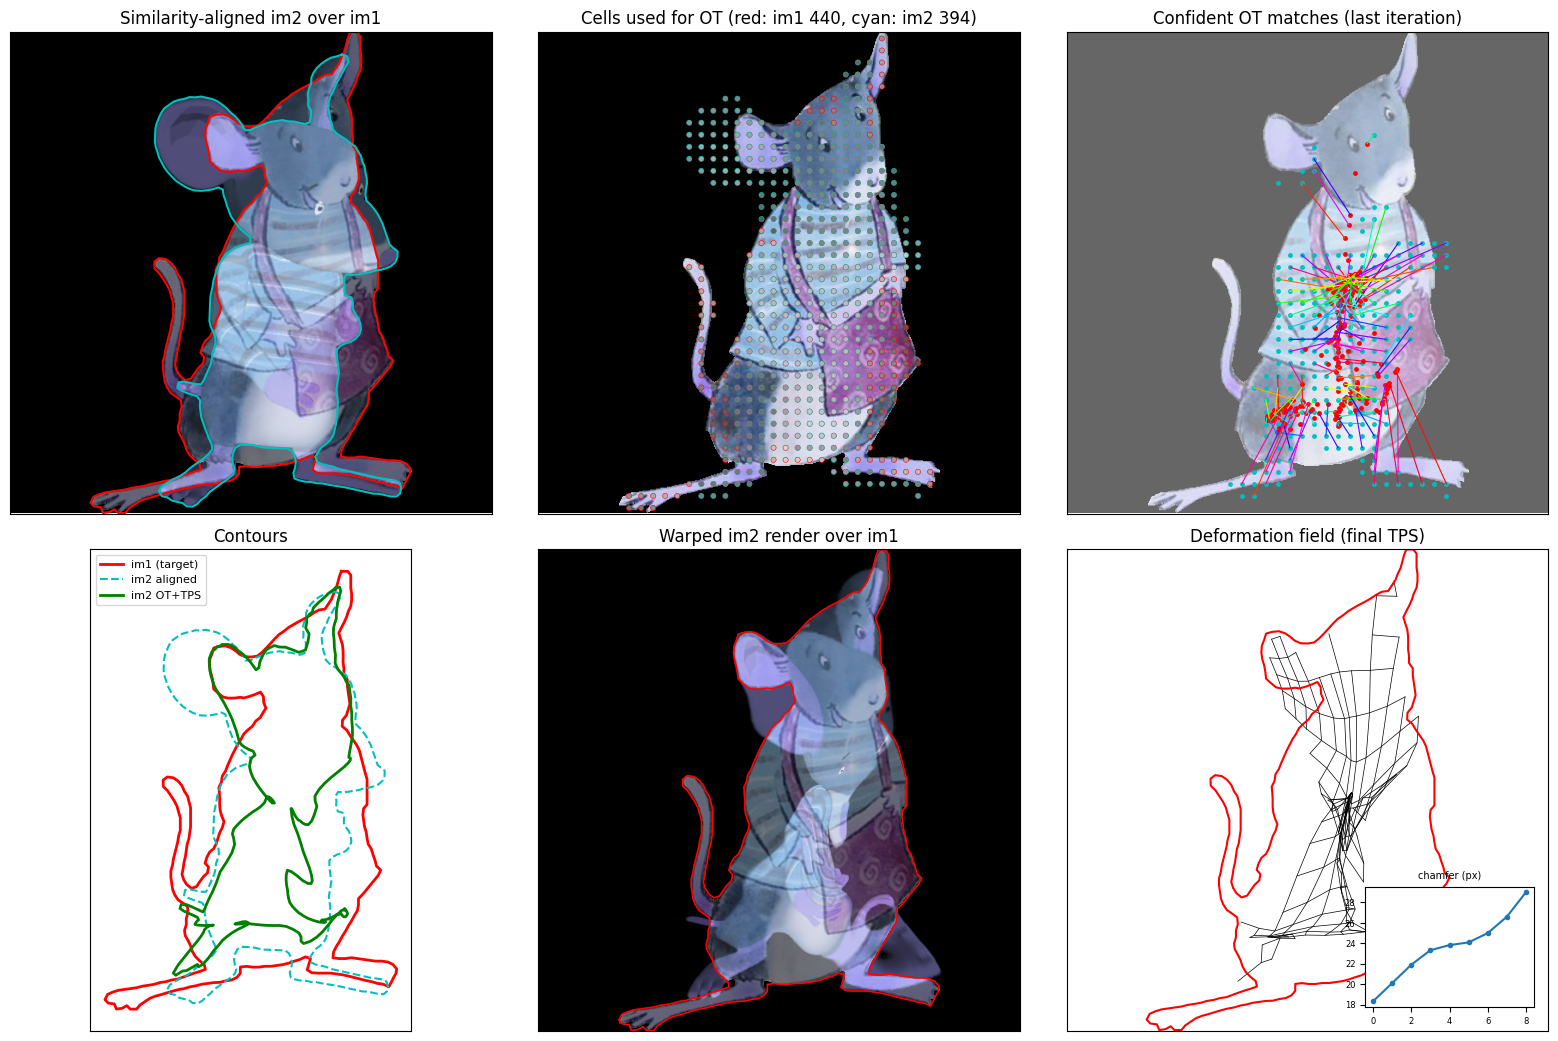

In [ ]:
"""
Drawing (im1) <- 3D render (im2) matching, combining
  1. contour similarity ICP (coarse alignment)
  2. annealed UNBALANCED optimal transport between coloured cells (soft matches,
     tail / bag are allowed to stay unmatched)
  3. thin-plate-spline (OpenCV) fitted on confident cell matches + contour anchors
  4. evaluation + visualization

Requirements:  pip install pot opencv-python scikit-learn matplotlib
Optional:      torch (DINOv2 features, set USE_DINO = True)

Expected variables in the notebook (BGR uint8 images, black background):
    im1, im2                 -> drawing and 3D render
    im1_contours, im2_contours -> the contour images you already extracted
"""
import numpy as np
import cv2
import ot
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

# ----------------------------------------------------------------------------
# Config
# ----------------------------------------------------------------------------
N_CONTOUR = 300        # points per contour
GRID      = 40         # number of cells along the longer image side
USE_DINO  = False      # add DINOv2 patch features to the Lab colour (needs torch + weights download)

N_ITERS   = 8
W_POS     = np.linspace(3.0, 0.4, N_ITERS)          # position weight: high (geometric) -> low (appearance)
REG_TPS   = np.geomspace(1.0, 0.02, N_ITERS)        # TPS stiffness (normalized coords): stiff -> flexible
W_COL     = 1.0    # weight of the Lab colour term
W_DINO    = 1.0    # weight of the DINO term (only if USE_DINO)
REG_OT    = 0.02   # entropic regularization
REG_M     = 0.5    # marginal relaxation: lower = more mass may stay unmatched (tail, bag)
KEEP_FRAC = 0.6    # fraction of most confident cells used to fit the TPS
CONT_KEEP = 0.7    # fraction of closest contour points used as TPS anchors
CONT_STEP = 2      # subsample contour anchors so they don't outweigh the cells

# ----------------------------------------------------------------------------
# 1. Masks, outlines, coarse similarity ICP
# ----------------------------------------------------------------------------
def largest_filled(img):
    """Filled silhouette mask (uint8 0/1) and its outer contour (N,2) in pixels."""
    g = img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    m = (g > 0).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    c = max(cnts, key=cv2.contourArea)
    filled = np.zeros_like(m)
    cv2.drawContours(filled, [c], -1, 1, thickness=cv2.FILLED)
    return filled, c[:, 0, :].astype(np.float64)

def resample_closed(c, n):
    c = np.vstack([c, c[:1]])
    d = np.r_[0, np.cumsum(np.linalg.norm(np.diff(c, axis=0), axis=1))]
    t = np.linspace(0, d[-1], n, endpoint=False)
    return np.c_[np.interp(t, d, c[:, 0]), np.interp(t, d, c[:, 1])]

def apply_T(T, p):
    return p @ T[:2, :2].T + T[:2, 2]

def moments_init(mask_src, mask_dst):
    ms = cv2.moments(mask_src, binaryImage=True)
    md = cv2.moments(mask_dst, binaryImage=True)
    cs = np.array([ms["m10"], ms["m01"]]) / ms["m00"]
    cd = np.array([md["m10"], md["m01"]]) / md["m00"]
    s = np.sqrt(md["m00"] / ms["m00"])
    return np.array([[s, 0, cd[0] - s * cs[0]],
                     [0, s, cd[1] - s * cs[1]],
                     [0, 0, 1.0]])

def trimmed_similarity_icp(src, dst, T0, iters=100, trim=0.8, tol=1e-6):
    """Trimmed ICP, 4-DoF similarity (cv2.estimateAffinePartial2D), transforms accumulated."""
    T = T0.copy()
    nn = NearestNeighbors(n_neighbors=1).fit(dst)
    for _ in range(iters):
        cur = apply_T(T, src)
        dist, idx = nn.kneighbors(cur)
        dist, idx = dist.ravel(), idx.ravel()
        keep = dist <= np.quantile(dist, trim)
        M, _ = cv2.estimateAffinePartial2D(cur[keep].astype(np.float32),
                                           dst[idx[keep]].astype(np.float32),
                                           method=cv2.LMEDS)
        if M is None:
            break
        T = np.vstack([M, [0, 0, 1]]) @ T
        if np.abs(M - np.eye(2, 3)).max() < tol:
            break
    return T

mask1, c1 = largest_filled(im1_contours)      # target (drawing)
mask2, c2 = largest_filled(im2_contours)      # source (3D render)
pts1 = resample_closed(c1, N_CONTOUR)
pts2 = resample_closed(c2, N_CONTOUR)
H, W = mask1.shape

T_sim   = trimmed_similarity_icp(pts2, pts1, moments_init(mask2, mask1))
pts2_al = apply_T(T_sim, pts2)                                           # aligned contour (px)
im2_al  = cv2.warpAffine(im2, T_sim[:2], (W, H), flags=cv2.INTER_LINEAR)
mask2_al = cv2.warpAffine(mask2, T_sim[:2], (W, H), flags=cv2.INTER_NEAREST)

# normalized coordinates -> all hyper-parameters are scale free
center = pts1.mean(0)
scale  = np.ptp(pts1, axis=0).max()
norm   = lambda p: (p - center) / scale
denorm = lambda p: p * scale + center

# ----------------------------------------------------------------------------
# 2. Cell features (blur + pooling, mask aware so the black background doesn't bleed)
# ----------------------------------------------------------------------------
CELL = max(H, W) / GRID
GH, GW = int(np.ceil(H / CELL)), int(np.ceil(W / CELL))

def lab_map(img, mask):
    m = mask.astype(np.float32)
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB).astype(np.float32) / 255.0
    sig = CELL / 2
    num = cv2.GaussianBlur(lab * m[..., None], (0, 0), sig)
    den = cv2.GaussianBlur(m, (0, 0), sig)
    num = cv2.resize(num, (GW, GH), interpolation=cv2.INTER_AREA)
    den = cv2.resize(den, (GW, GH), interpolation=cv2.INTER_AREA)
    cov = cv2.resize(m, (GW, GH), interpolation=cv2.INTER_AREA)       # foreground coverage
    return num / np.maximum(den[..., None], 1e-6), cov

def dino_map(img_bgr):
    import torch
    import torch.nn.functional as Fn
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    if not hasattr(dino_map, "model"):
        dino_map.model = torch.hub.load("facebookresearch/dinov2", "dinov2_vitb14").to(dev).eval()
    rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    h, w = rgb.shape[:2]
    s = 448 / max(h, w)
    nh, nw = int(round(h * s / 14)) * 14, int(round(w * s / 14)) * 14
    x = cv2.resize(rgb, (nw, nh), interpolation=cv2.INTER_AREA).astype(np.float32) / 255.0
    x = ((x - np.array([0.485, 0.456, 0.406], np.float32)) / np.array([0.229, 0.224, 0.225], np.float32))
    x = torch.from_numpy(x.transpose(2, 0, 1))[None].to(dev)
    with torch.no_grad():
        f = dino_map.model.forward_features(x)["x_norm_patchtokens"]      # (1, N, D)
    f = f.reshape(1, nh // 14, nw // 14, -1).permute(0, 3, 1, 2)
    f = Fn.interpolate(f, size=(GH, GW), mode="bilinear", align_corners=False)
    return f[0].permute(1, 2, 0).cpu().numpy()                            # (GH, GW, D)

def cells(img, mask):
    lab, cov = lab_map(img, mask)
    ys, xs = np.nonzero(cov > 0.5)
    pos = np.c_[(xs + 0.5) * W / GW, (ys + 0.5) * H / GH].astype(np.float64)
    return lab, cov, ys, xs, pos

lab1, cov1, ys1, xs1, pos1 = cells(im1, mask1)         # target cells
lab2, cov2, ys2, xs2, pos2 = cells(im2_al, mask2_al)   # source cells (already similarity-aligned)

F1 = W_COL * lab1[ys1, xs1].astype(np.float64)
F2 = W_COL * lab2[ys2, xs2].astype(np.float64)

if USE_DINO:
    d1, d2 = dino_map(im1)[ys1, xs1], dino_map(im2_al)[ys2, xs2]
    allf = np.vstack([d1, d2]); mu = allf.mean(0)
    _, _, Vt = np.linalg.svd(allf - mu, full_matrices=False)               # joint PCA -> shared space
    proj = lambda d: ((d - mu) @ Vt[:8].T)
    z1, z2 = proj(d1), proj(d2)
    sd = np.vstack([z1, z2]).std()
    F1 = np.hstack([F1, W_DINO * z1 / sd * 0.5])
    F2 = np.hstack([F2, W_DINO * z2 / sd * 0.5])

a = cov2[ys2, xs2].astype(np.float64); a /= a.sum()
b = cov1[ys1, xs1].astype(np.float64); b /= b.sum()

# ----------------------------------------------------------------------------
# 3. TPS wrapper (cv2) + unbalanced OT solver
# ----------------------------------------------------------------------------
class TPS:
    """cv2.ThinPlateSplineShapeTransformer mapping src -> dst.
    OpenCV's argument order is confusing, so both orders are tried and the one that
    really sends src onto dst is kept."""
    def __init__(self, src, dst, reg):
        s = src.reshape(1, -1, 2).astype(np.float32)
        d = dst.reshape(1, -1, 2).astype(np.float32)
        m = [cv2.DMatch(i, i, 0) for i in range(len(src))]
        best = None
        for p, q in ((d, s), (s, d)):
            t = cv2.createThinPlateSplineShapeTransformer(float(reg))
            t.estimateTransformation(p, q, m)
            err = np.linalg.norm(t.applyTransformation(s)[1][0] - dst, axis=1).mean()
            if best is None or err < best[0]:
                best = (err, t)
        self.t = best[1]
    def __call__(self, p):
        return self.t.applyTransformation(p.reshape(1, -1, 2).astype(np.float32))[1][0].astype(np.float64)

def solve_ot(a, b, M):
    for reg in (REG_OT, REG_OT * 2, REG_OT * 5):
        for method in ("sinkhorn_stabilized", "sinkhorn"):
            try:
                P = ot.unbalanced.sinkhorn_unbalanced(a, b, M, reg, REG_M, method=method, numItermax=2000)
            except Exception:
                continue
            if np.all(np.isfinite(P)) and P.sum() > 1e-8:
                return P
    raise RuntimeError("Unbalanced Sinkhorn failed: try a larger REG_OT or REG_M")

def chamfer(p, q):
    da = NearestNeighbors(n_neighbors=1).fit(q).kneighbors(p)[0].mean()
    db = NearestNeighbors(n_neighbors=1).fit(p).kneighbors(q)[0].mean()
    return 0.5 * (da + db)

# ----------------------------------------------------------------------------
# 4. Annealed OT + TPS
# ----------------------------------------------------------------------------
P1n, c1n = norm(pos1), norm(pts1)                 # target cells / contour (normalized)
S2n, c2n = norm(pos2), norm(pts2_al)              # aligned source cells / contour (normalized)
cur_cells, cur_cont = S2n.copy(), c2n.copy()
nn_c1 = NearestNeighbors(n_neighbors=1).fit(c1n)
color_cost = ot.dist(F2, F1)                      # (n2, n1) squared distance in feature space
color_cost /= color_cost.max()

history = [chamfer(denorm(cur_cont), pts1)]
for k, (wp, reg) in enumerate(zip(W_POS, REG_TPS)):
    # cost: appearance + distance between the CURRENT (deformed) source cells and the target cells
    pos_cost = ot.dist(cur_cells, P1n)
    pos_cost /= pos_cost.max()
    M = color_cost + wp * pos_cost
    M /= M.max()
    P = solve_ot(a, b, M)

    mass = P.sum(1)
    conf = mass / a                                                  # relative transported mass
    tgt = (P @ P1n) / np.maximum(mass[:, None], 1e-300)              # barycentric target of each cell
    keep = conf >= np.quantile(conf, 1 - KEEP_FRAC)

    # contour anchors: closest target contour point, trimmed
    d, idx = nn_c1.kneighbors(cur_cont)
    d, idx = d.ravel(), idx.ravel()
    ck = np.where(d <= np.quantile(d, CONT_KEEP))[0][::CONT_STEP]

    src_a = np.vstack([S2n[keep], c2n[ck]])                          # always fit from the aligned source
    dst_a = np.vstack([tgt[keep], c1n[idx[ck]]])
    tps_fwd = TPS(src_a, dst_a, reg)
    cur_cells, cur_cont = tps_fwd(S2n), tps_fwd(c2n)
    history.append(chamfer(denorm(cur_cont), pts1))
    print(f"iter {k+1}/{N_ITERS}  w_pos={wp:.2f}  tps_reg={reg:.3f}  "
          f"kept cells={keep.sum()}/{len(keep)}  chamfer={history[-1]:.2f}px")

last_keep, last_tgt = keep, tgt
pts2_def = denorm(cur_cont)            # pts2_def[i] = where pts2[i] (resampled im2 contour) ends up
cells_def = denorm(cur_cells)

# image warp: backward TPS (output pixel -> aligned-source pixel), evaluated on a coarse grid
def warp_with_backward_tps(img, src_n, dst_n, reg, interp=cv2.INTER_LINEAR, step=4):
    back = TPS(dst_n, src_n, reg)
    gx, gy = np.meshgrid(np.arange(0, W, step), np.arange(0, H, step))
    grid = np.c_[gx.ravel(), gy.ravel()].astype(np.float64)
    mp = denorm(back(norm(grid))).reshape(gy.shape + (2,)).astype(np.float32)
    mp = cv2.resize(mp, (W, H), interpolation=cv2.INTER_LINEAR)
    return cv2.remap(img, mp[..., 0], mp[..., 1], interp, borderMode=cv2.BORDER_CONSTANT, borderValue=0)

warped_im2   = warp_with_backward_tps(im2_al, src_a, dst_a, REG_TPS[-1])
warped_mask2 = warp_with_backward_tps(mask2_al, src_a, dst_a, REG_TPS[-1], interp=cv2.INTER_NEAREST)

# ----------------------------------------------------------------------------
# 5. Evaluation
# ----------------------------------------------------------------------------
def iou(m1, m2):
    return (m1 & m2).sum() / max((m1 | m2).sum(), 1)

sc_ext, hd_ext = cv2.createShapeContextDistanceExtractor(), cv2.createHausdorffDistanceExtractor()
cvs = lambda p: p.astype(np.float32).reshape(-1, 1, 2)
sub = lambda p: cvs(p[:: max(1, len(p) // 150)])

# IoU of the original (unaligned) masks only makes sense after resizing, so start at "similarity"
rows = [("similarity", pts2_al, mask2_al), ("OT + TPS", pts2_def, warped_mask2)]
print(f"\n{'stage':<12}{'shape-ctx':>11}{'Hausdorff':>11}{'chamfer':>9}{'mask IoU':>10}")
for name, p, m in rows:
    print(f"{name:<12}{sc_ext.computeDistance(sub(p), sub(pts1)):>11.4f}"
          f"{hd_ext.computeDistance(cvs(p), cvs(pts1)):>11.2f}"
          f"{chamfer(p, pts1):>9.2f}{iou(m.astype(bool), mask1.astype(bool)):>10.3f}")

# ----------------------------------------------------------------------------
# 6. Visualization
# ----------------------------------------------------------------------------
rgb = lambda x: cv2.cvtColor(x, cv2.COLOR_BGR2RGB)
loop = lambda p: np.vstack([p, p[:1]])

fig, axs = plt.subplots(2, 3, figsize=(16, 10.5))

# (a) coarse alignment overlay
ax = axs[0, 0]
ax.imshow(cv2.addWeighted(rgb(im1), 0.5, rgb(im2_al), 0.5, 0))
ax.plot(*loop(pts1).T, "r-", lw=1.5); ax.plot(*loop(pts2_al).T, "c-", lw=1.5)
ax.set_title("Similarity-aligned im2 over im1")

# (b) cell grids
ax = axs[0, 1]
ax.imshow(rgb(im1))
ax.scatter(*pos1.T, s=14, c=np.clip(lab1[ys1, xs1][:, [0, 0, 0]], 0, 1), edgecolors="r", linewidths=0.4)
ax.scatter(*pos2.T, s=14, c=np.clip(lab2[ys2, xs2][:, [0, 0, 0]], 0, 1), edgecolors="c", linewidths=0.4)
ax.set_title(f"Cells used for OT (red: im1 {len(pos1)}, cyan: im2 {len(pos2)})")

# (c) OT matches of the last iteration
ax = axs[0, 2]
ax.imshow(rgb(im1), alpha=0.6)
tg = denorm(last_tgt)
for i in np.where(last_keep)[0][::2]:
    ax.plot([pos2[i, 0], tg[i, 0]], [pos2[i, 1], tg[i, 1]], "-", lw=0.8, color=plt.cm.hsv((i % 97) / 97))
ax.scatter(*pos2[last_keep].T, s=6, c="c"); ax.scatter(*tg[last_keep].T, s=6, c="r")
ax.set_title("Confident OT matches (last iteration)")

# (d) contours
ax = axs[1, 0]
ax.plot(*loop(pts1).T, "r-", lw=2, label="im1 (target)")
ax.plot(*loop(pts2_al).T, "c--", lw=1.5, label="im2 aligned")
ax.plot(*loop(pts2_def).T, "g-", lw=2, label="im2 OT+TPS")
ax.set_aspect("equal"); ax.invert_yaxis(); ax.legend(fontsize=8); ax.set_title("Contours")

# (e) warped render
ax = axs[1, 1]
ax.imshow(cv2.addWeighted(rgb(im1), 0.5, rgb(warped_im2), 0.5, 0))
ax.plot(*loop(pts1).T, "r-", lw=1.2)
ax.set_title("Warped im2 render over im1")

# (f) deformation grid + convergence
ax = axs[1, 2]
gx, gy = np.meshgrid(np.linspace(0, W - 1, 28), np.linspace(0, H - 1, 28))
g = np.c_[gx.ravel(), gy.ravel()]
inside = mask2_al[np.clip(g[:, 1].astype(int), 0, H - 1), np.clip(g[:, 0].astype(int), 0, W - 1)] > 0
gd = denorm(tps_fwd(norm(g))).reshape(gx.shape + (2,))
gd[~inside.reshape(gx.shape)] = np.nan
for i in range(gx.shape[0]):
    ax.plot(gd[i, :, 0], gd[i, :, 1], "k-", lw=0.5); ax.plot(gd[:, i, 0], gd[:, i, 1], "k-", lw=0.5)
ax.plot(*loop(pts1).T, "r-", lw=1.5)
ax.set_xlim(0, W); ax.set_ylim(H, 0); ax.set_aspect("equal")
ins = ax.inset_axes([0.62, 0.05, 0.35, 0.25])
ins.plot(history, "o-", ms=3); ins.set_title("chamfer (px)", fontsize=7); ins.tick_params(labelsize=6)
ax.set_title("Deformation field (final TPS)")

for ax in axs.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

# Dense correspondence you can reuse:
#   pts2[i]  (im2 contour, original pixels)  ->  pts2_def[i]  (position in im1 pixels)